On modélise un qunatum reservoir.

Le but est de déterminer quel est la meilleure heuristique quantique pour faire aggrandir l'espace dans lequel vit les X_i

Notre problématique est d'essayer d'avoir le meilleur training quantique pour nos données.

Faut-il beaucoup/pas beaucoup d'intrication ? Mettre des R_z ?

## Génération des paramètres

(Par Victor)

In [10]:


from scipy.integrate import odeint
import matplotlib.pyplot as plt
import numpy as np
import random


# These are our constants
N = 4 # Number of variables
F = 8  # Forcing


def L96(x, t):
    """Lorenz 96 model with constant forcing"""
    return (np.roll(x, -1) - np.roll(x, 2)) * np.roll(x, 1) - x + F


x0 = F * np.ones(N)  # Initial state (equilibrium)
x0[0] += 0.01*random.uniform(0,1)  # Add small perturbation to the first variable
t = np.arange(0.0, 30.0, 0.01)

xs = odeint(L96, x0, t)
x_data=np.abs(xs)/np.max(np.abs(xs))



## Générateur de circuits paramétrés
Structure : `H` → pour chaque couche d'intrication `l` ∈ [0, nb_ring) : (RY **données** si `l < nb_encode`, sinon RY **aléatoires**) → couche d'intrication (paramètre `I`) → RY aléatoires finaux.
Avec `nb_ring=3, nb_encode=2, I=0` on retrouve exactement ton circuit exemple.

[628531815, 2997404415, 625913126]
OrderedDict({'cx': 42, 'ry': 32, 'h': 8, 'barrier': 3})


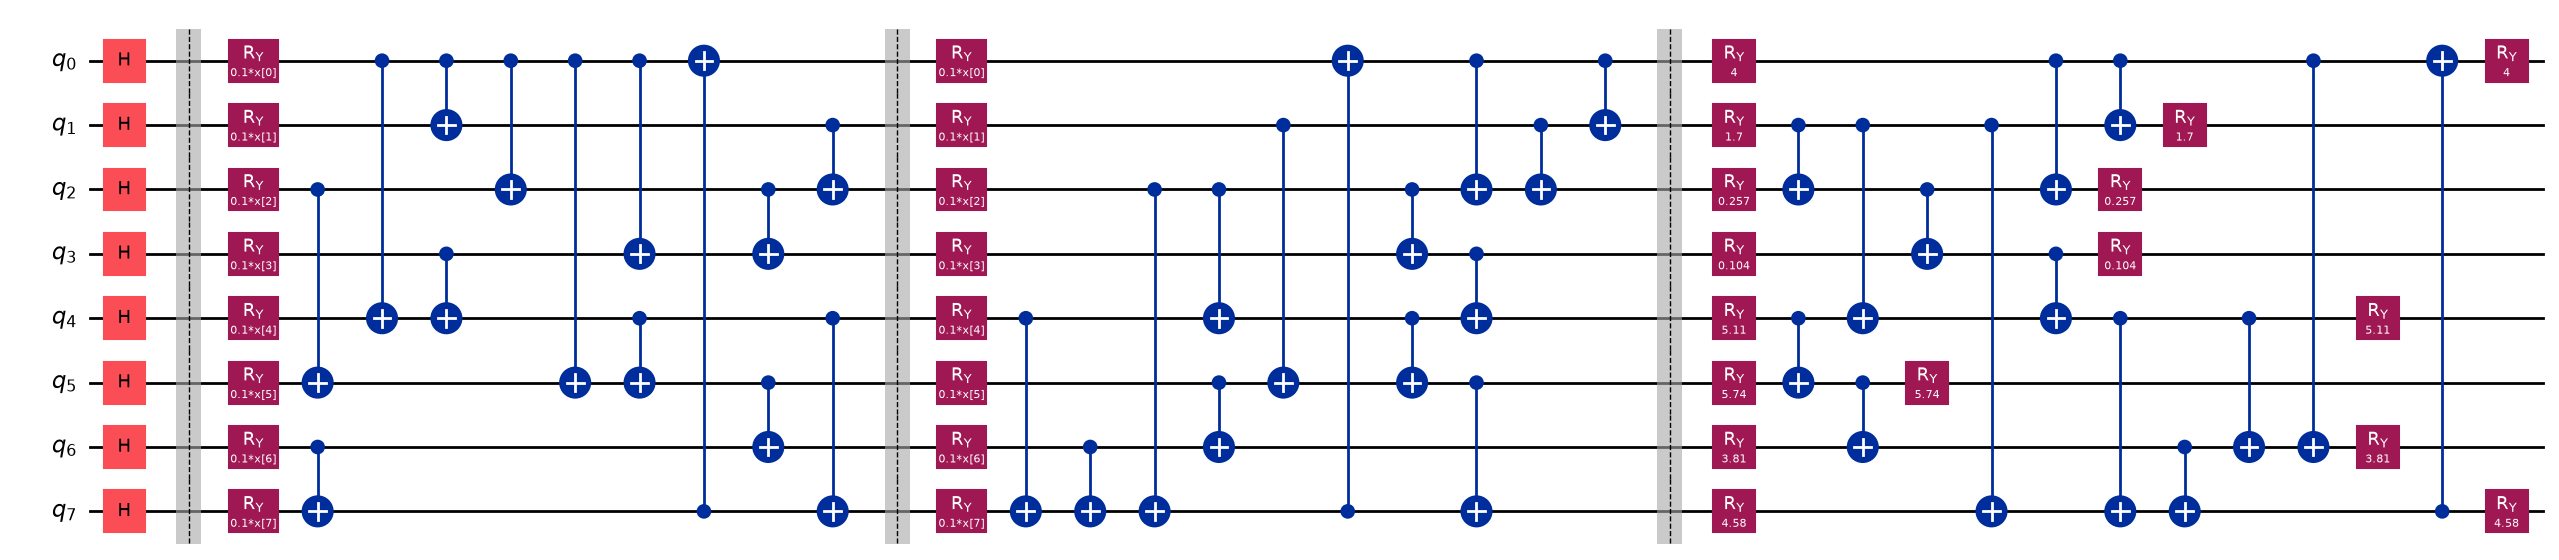

In [11]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, partial_trace, entropy

def entangling_layer(qc, n, I, rng, gate="cx"):
    """I=0 : anneau (n portes). I=1 : toutes les paires (n(n-1)/2 portes).
    Entre les deux : l'anneau + une fraction I des paires restantes, tirées au hasard,
    puis ordre des portes mélangé."""
    ring = [(i, (i + 1) % n) for i in range(n)]
    ring_set = {frozenset(p) for p in ring}
    others = [(i, j) for i in range(n) for j in range(i + 1, n)
              if frozenset((i, j)) not in ring_set]
    n_extra = int(round(I * len(others)))
    extra = [others[k] for k in rng.choice(len(others), n_extra, replace=False)] if n_extra else []
    gates = ring + extra
    if extra:
        gates = [gates[k] for k in rng.permutation(len(gates))]
    for a, b in gates:
        getattr(qc, gate)(a, b)

def encode_layer(qc, x, lam, n):
    """ On encode 
    """
    # feature k -> qubit k % n  (si n < K, plusieurs features partagent un qubit)
    for k in range(len(x)):
        qc.ry(lam * x[k], k % n)

def build_circuit(K=8, n_qubits=None, I=0.0, nb_ring=3, nb_encode=2,
                  lam=0.01, alpha_range=2*np.pi, seed=0, I_seeds=None,
                  gate="cx", shared_alpha=True):
    """ K: longueur de X_i, n_qubits > K, 0<I<1, nb_ring : nb de fois qu'on applqiue des rings ;
      nb_encode : nb de fois qu'on encore, après on applique des truc aléatoires dépendant de SEED (il faut à chaque fois la meme chose)
      Par défaut on applique des cx mais il est plus naturel ici d'utiliser des cz ?
      si sahred_alpha:True, toujours le même vecteur aléatoire appiqué à chq layer
      lam : facteur d'échelle
    """
    
    n = n_qubits or K
    nb_encode = min(nb_encode, nb_ring)

    if I_seeds is None or isinstance(I_seeds, (int, np.integer)):
        I_seeds = np.random.default_rng(I_seeds).integers(0, 2**32, nb_ring).tolist()
    else:
        I_seeds = [int(s) for s in I_seeds]
        assert len(I_seeds) == nb_ring, "I_seeds doit contenir nb_ring entiers"

    rng = np.random.default_rng(seed)
    alpha = rng.uniform(0, alpha_range, n)
    x = ParameterVector("x", K)

    qc = QuantumCircuit(n)
    qc.h(range(n))
    for layer in range(nb_ring):
        qc.barrier()
        if layer < nb_encode:
            encode_layer(qc, x, lam, n)
        else:
            a = alpha if shared_alpha else rng.uniform(0, alpha_range, n)
            for q in range(n): qc.ry(a[q], q)
        entangling_layer(qc, n, I, np.random.default_rng(I_seeds[layer]), gate)
    a = alpha if shared_alpha else rng.uniform(0, alpha_range, n)
    for q in range(n): qc.ry(a[q], q)

    def circuit(u, state=False):
        sv = Statevector(qc.assign_parameters({x: np.asarray(u)}))
        return sv if state else sv.probabilities()

    return circuit,qc , I_seeds

circuit, qc, I_seeds = build_circuit(K=8, I=0.3, nb_ring=3, nb_encode=2, lam=0.1)
print(I_seeds)                       # ex. [2810034, 913377, 4021100]

# Rejouer exactement le même circuit
circuit2, qc2, _ = build_circuit(K=8, I=0.3, nb_ring=3, nb_encode=2, lam=0.1, I_seeds=I_seeds)

# Garder le même motif d'intrication en variant I ou alpha
circuit3, _, _ = build_circuit(K=8, I=0.6, nb_ring=3, nb_encode=2, lam=0.1, I_seeds=I_seeds, seed=1)
print(qc.count_ops()); qc.draw("mpl", fold=-1, style="iqx")

In [12]:
def compute_states(circuit, X):
    """États exacts, calculés une seule fois (shape : N x 2^n)."""
    return np.array([circuit(u, state=True).data for u in X])

def features_from_states(psi, n, mode="probs", shots=None, seed=0):
    """mode : 'state' (idéal, non mesurable) | 'probs' | 'z' | 'zz' (= Z_i et Z_iZ_j, i<j)
    shots=None : valeurs exactes ; sinon : estimation à partir de `shots` bitstrings."""
    if mode == "state":
        return np.hstack([psi.real, psi.imag])
    rng = np.random.default_rng(seed)
    p = np.abs(psi)**2
    p /= p.sum(1, keepdims=True)
    if shots is not None:
        p = np.array([rng.multinomial(shots, row) for row in p]) / shots
    if mode == "probs":
        return p
    k = np.arange(2**n)
    Zs = 1 - 2*((k[:, None] >> np.arange(n)) & 1)          # signe de Z_q sur chaque bitstring
    if mode == "z":
        return p @ Zs
    if mode == "zz":
        ZZs = np.stack([Zs[:, i]*Zs[:, j] for i in range(n) for j in range(i+1, n)], 1)
        return np.hstack([p @ Zs, p @ ZZs])
    raise ValueError(mode)

## Fin


In [13]:


# -*- coding: utf-8 -*-
"""
Created on Mon Oct 26 12:28:09 2026

@author: adrie
"""
"""
Couche de sortie (readout) d'un reservoir computer : régression ridge -> W_out.

Le coeur du code est dans train_readout() et predict().
Le reste (L96 + faux réservoir) sert uniquement à tester. Pour ton vrai QRC,
remplace FakeReservoir.features() par la fonction qui renvoie les mesures
de ton circuit quantique (probabilités ou valeurs d'espérance).
"""
import numpy as np
from sklearn.linear_model import Ridge


# ----------------------------------------------------------------------
# 1. LE COEUR : entraînement et utilisation du readout
# ----------------------------------------------------------------------
def train_readout(R, Y, alpha=1e-6):
    """
    R : (T, D)  matrice des états du réservoir (une ligne = un pas de temps)
    Y : (T, N)  cibles (l'état L96 au pas de temps suivant)
    Renvoie le modèle sklearn ; W_out = model.coef_ de forme (N, D).
    """
    model = Ridge(alpha=alpha, fit_intercept=False)
    model.fit(R, Y)
    return model


def predict(model, r):
    """r : (D,) état du réservoir -> (N,) prédiction  (= W_out @ r)."""
    return model.predict(r[None, :])[0]


# ----------------------------------------------------------------------
# 2. DONNÉES : Lorenz 96
# ----------------------------------------------------------------------


def simulate_l96(N=8, F=8.0, dt_int=0.01, dt_out=0.05, n_out=6000, spinup=1000):
    x = F * np.ones(N)
    x[0] += 0.01
    sub = int(round(dt_out / dt_int))
    out = []
    for i in range(spinup + n_out):
        for _ in range(sub):  # RK4
            k1 = l96_rhs(x, F)
            k2 = l96_rhs(x + 0.5 * dt_int * k1, F)
            k3 = l96_rhs(x + 0.5 * dt_int * k2, F)
            k4 = l96_rhs(x + dt_int * k3, F)
            x = x + dt_int / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        if i >= spinup:
            out.append(x.copy())
    return np.array(out)


# ----------------------------------------------------------------------
# 3. FAUX RÉSERVOIR (à remplacer par le circuit quantique)
# ----------------------------------------------------------------------
class FakeReservoir:
    """Features aléatoires fixes : cos(W u + b). Sans mémoire (recurrence-free)."""

    def __init__(self, n_in, n_feat=1000, scale=0.3, seed=0):
        rng = np.random.default_rng(seed)
        self.W = scale * rng.standard_normal(size=(n_feat, n_in))
        self.b = rng.uniform(0, 2 * np.pi, n_feat)

    def features(self, u):
        return np.cos(self.W @ u + self.b)


# ----------------------------------------------------------------------
# 4. TEST COMPLET
# ----------------------------------------------------------------------
def test_V():
    if __name__ == "__main__":
        N, dt_out, LYAP = 8, 0.05, 1.7          # LYAP ~ lambda_max approximatif
        data = x_data

        # normalisation (important : les entrées deviennent des angles)
        mu, sd = data.mean(0), data.std(0)
        U = (data - mu) / sd

        n_train = 4000
        U_train, U_test = U[:n_train + 1], U[n_train:]

        res = compute_states(circuit,U_train)

        # --- entraînement : R[i] = features(u_i), cible Y[i] = u_{i+1}
        R = np.array([res.features(u) for u in U_train[:-1]])   # (T, D)
        Y = U_train[1:]                                          # (T, N)
        model = train_readout(R, Y, alpha=1e-6)
        W_out = model.coef_
        print("Forme de W_out :", W_out.shape)

        # --- prévision en boucle fermée
        n_steps = 200
        u = U_test[0].copy()
        preds = []
        for _ in range(n_steps):
            u = predict(model, res.features(u))   # la sortie redevient l'entrée
            preds.append(u)
        preds = np.array(preds)
        truth = U_test[1:n_steps + 1]

        err = np.linalg.norm(preds - truth, axis=1) / np.sqrt(N)
        t_lyap = np.arange(1, n_steps + 1) * dt_out * LYAP
        bad = np.where(err > 0.5)[0]
        valid = t_lyap[bad[0]] if len(bad) else t_lyap[-1]
        print(f"Temps de prévision valide (erreur < 0.5) : {valid:.1f} temps de Lyapunov")



ImportError: scipy._cyutility does not export expected C function __pyx_FusedFunction_New

In [ ]:
test_V()

NameError: name 'test_V' is not defined